# SokoRadar: alerts and early warning

**Goal:** label every market month as Normal, Stress, Alert or Crisis, then build an early warning model that says
**which markets are likely to hit Alert or Crisis in the next 1 to 3 months**, and prove how many months earlier it
warns than WFP's current alert.

**Plan**
1. Load what the EDA saved
2. ALPS phases for the national prices
3. ALPS phases for every county market (the answer sheet)
4. Build the early warning dataset (what we know each month, and what happened next)
5. Backtest the early warning model year by year, and choose the alert threshold on the training years
6. Final test on 2025 to 2026, run once
7. Lead time: how many months earlier we warn, including the 2011, 2017 and 2022 droughts
8. Save the results for the app

**Rules we keep:** only real prices are scored; every prediction uses past information only; the threshold is chosen
on the training years; the test years are used once at the end.

## Step 1. Load what the EDA saved

In [1]:
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# find the handoff folder saved by 01_eda_review
here = Path.cwd()
places = [p / 'output' / 'modelling' / 'handoff' for p in [here, *here.parents]] + \
         [p / 'handoff' for p in [here, *here.parents]]
HANDOFF = next((p for p in places if (p / 'meta.json').exists()), None)
assert HANDOFF is not None, 'Handoff folder not found. Run 01_eda_review first.'

# plan settings from the EDA
meta = json.load(open(HANDOFF / 'meta.json'))
CORE, TRAIN, TEST = meta['CORE'], meta['TRAIN'], meta['TEST']

# national prices and the real/estimated flag
P = pd.read_csv(HANDOFF / 'national_prices.csv', index_col=0)
P.index = pd.PeriodIndex(P.index, freq='M')
REAL = pd.read_csv(HANDOFF / 'national_real_flag.csv', index_col=0)
REAL.index = pd.PeriodIndex(REAL.index, freq='M')

# WFP county market prices (real only)
led = pd.read_csv(HANDOFF / 'real_ledger.csv')

print('Handoff folder:', HANDOFF)
print('Core crops:', CORE)
print('Train:', TRAIN, '| Test:', TEST)
print('National prices:', P.shape, '|', P.index.min(), 'to', P.index.max())
print('Real share of core crops:')
print(REAL[CORE].mean().round(2))
print('WFP county rows:', len(led))
print('WFP columns:', led.columns.tolist())

Handoff folder: c:\Users\siraa\OneDrive\Desktop\Data-science\sokoradar\output\modelling\handoff
Core crops: ['Dry Maize', 'Sorghum', 'Beans Rosecoco', 'Red Irish Potatoes']
Train: ['2006-01', '2024-12'] | Test: ['2025-01', '2026-09']
National prices: (228, 17) | 2006-01 to 2024-12
Real share of core crops:
Dry Maize             0.82
Sorghum               0.82
Beans Rosecoco        0.82
Red Irish Potatoes    0.82
dtype: float64
WFP county rows: 9413
WFP columns: ['admin2', 'market', 'crop', 'pricetype', 'month', 'kes_kg', 'n_rows', 'flag']


**What the output shows**

1. The notebook found the handoff folder saved by 01_eda_review, so it uses the same data and rules as the EDA.
2. We work on 4 core crops: dry maize, sorghum, beans (Rosecoco) and potatoes (red Irish). The other bean and potato types were dropped in the EDA because they are copies of these.
3. Training years are 2006 to 2024, and test years are 2025 to September 2026. We set everything on the training years and use the test years only once, at the end.
4. National prices cover 228 months (19 years) for 17 commodities, but we use only the 4 core crops.
5. 82% of the core crop months are real prices. The other 18% are estimated, mostly 2022 to 2024. We score alerts on real months only.
6. The WFP county file has 9,413 real market prices, with county, market, crop, retail or wholesale, month and price in KES per kg.

## Step 2. ALPS phases for the national prices

For each crop and month we ask: is the price unusually high for this time of year? A line (long term trend plus the
normal monthly pattern) is fitted on **earlier real months only**, and the ALPS score measures how far this month's price
sits above it, in units of the usual error. Normal below 0.25, Stress 0.25 to 1, Alert 1 to 2, Crisis 2 and above.

First scored month: 2009-01
              crop  basis  Normal  Stress  Alert  Crisis  Alert or Crisis %
         Dry Maize  [EST]     131      18     16      27               22.4
         Dry Maize [REAL]     120      13     14       5               12.5
           Sorghum  [EST]     119      18     27      28               28.6
           Sorghum [REAL]     110      18     19       5               15.8
    Beans Rosecoco  [EST]     136      18      9      29               19.8
    Beans Rosecoco [REAL]     128      15      5       4                5.9
Red Irish Potatoes  [EST]     110      26     34      22               29.2
Red Irish Potatoes [REAL]      98      19     24       9               22.0


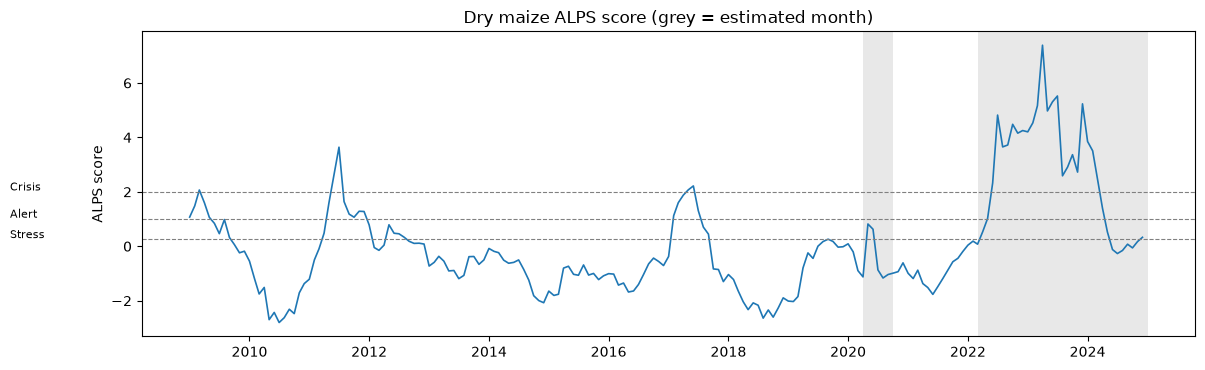

In [2]:
PHASES = ['Normal', 'Stress', 'Alert', 'Crisis']

def alps_scores(price, use, min_obs=36):
    """ALPS score per month, using a trend + season fit on earlier real months only."""
    price = price.astype(float)
    t = np.arange(len(price))
    month = price.index.month
    X = np.column_stack([np.ones(len(price)), t] + [(month == m).astype(float) for m in range(2, 13)])
    out = pd.Series(np.nan, index=price.index)
    for i in range(len(price)):
        past = np.where(use.values[:i] & price.notna().values[:i])[0]
        if len(past) < min_obs or np.isnan(price.iloc[i]):
            continue
        beta, *_ = np.linalg.lstsq(X[past], price.values[past], rcond=None)
        resid = price.values[past] - X[past] @ beta
        sd = resid.std(ddof=X.shape[1])
        out.iloc[i] = (price.iloc[i] - X[i] @ beta) / sd
    return out

def to_phase(score):
    return pd.cut(score, [-np.inf, 0.25, 1, 2, np.inf], right=False, labels=PHASES)

ALPS = pd.DataFrame({c: alps_scores(P[c], REAL[c].astype(bool)) for c in CORE})
PH = ALPS.apply(to_phase)

rows = []
for c in CORE:
    for basis, mask in [('[EST]', PH[c].notna()), ('[REAL]', PH[c].notna() & REAL[c].astype(bool))]:
        vc = PH.loc[mask, c].value_counts().reindex(PHASES, fill_value=0)
        rows.append({'crop': c, 'basis': basis, **vc.to_dict(),
                     'Alert or Crisis %': round(100 * vc[['Alert', 'Crisis']].sum() / vc.sum(), 1)})
print('First scored month:', ALPS['Dry Maize'].first_valid_index())
print(pd.DataFrame(rows).to_string(index=False))

s = ALPS['Dry Maize']
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(s.index.to_timestamp(), s.values, lw=1.2)
for y, lab in [(0.25, 'Stress'), (1, 'Alert'), (2, 'Crisis')]:
    ax.axhline(y, ls='--', lw=0.8, color='grey'); ax.text(s.index[0].to_timestamp(), y + 0.05, lab, fontsize=8)
for m in s.index[~REAL['Dry Maize'].astype(bool) & s.notna()]:
    ax.axvspan(m.to_timestamp(), (m + 1).to_timestamp(), color='lightgrey', alpha=0.5, lw=0)
ax.set_title('Dry maize ALPS score (grey = estimated month)'); ax.set_ylabel('ALPS score')
plt.tight_layout(); plt.show()

**What the output shows**

1. ALPS scores start in January 2009, once there are 36 real months to learn the normal price pattern.
2. Estimated months inflate crises. Dry maize has 27 Crisis months when estimated months are included, but only 5 on real months. Most of the difference comes from 2022 to 2024, when national prices are estimates. This is why we score alerts on real months only.
3. On real months, Alert or Crisis happens in 12.5% of months for maize, 15.8% for sorghum, 5.9% for beans and 22.0% for potatoes. Potatoes are the most volatile crop, which matches the EDA.
4. Most months are Normal (120 of 152 real maize months). Price shocks are rare, so the alert model must be judged on how many of these rare months it catches (recall), not on overall accuracy.

**What the chart shows**

1. The maize ALPS score rises above the Alert and Crisis lines in 2011 and 2017, both known drought years in Kenya, so the score picks up real food price shocks.
2. Negative scores, for example in 2010 and 2018 to 2019, mean maize was cheaper than usual, often after good harvests.
3. The highest peak, about 6.5 in 2023, sits in the grey estimated period. Its size cannot be trusted, and it explains most of the extra Crisis months in the [EST] rows.
4. Conclusion: ALPS works on real months, and estimated months should not be used to judge alerts.

## Step 3. ALPS phases for every county market (the answer sheet)

The same method for every WFP market series (one market, one crop, retail or wholesale) with at least 3 years of real
prices. These labels are what actually happened. The early warning model is judged against them.

Series scored: 71 | scored market-months: 3926
phase            Normal  Stress  Alert  Crisis  Alert or Crisis %
crop     period                                                  
Beans    test       180       2      1       0                0.5
         train      685     131     71      48               12.7
Maize    test       153      15      4       0                2.3
         train     1104     161    106      73               12.4
Potatoes test        86      10      6       1                6.8
         train      346      84     93      40               23.6
Sorghum  test         1       0      0       0                0.0
         train      367      64     54      40               17.9

Test period: series 44 | months 21 | Alert or Crisis market-months: 12
Saved: c:\Users\siraa\OneDrive\Desktop\Data-science\sokoradar\output\modelling\handoff\county_alps.csv


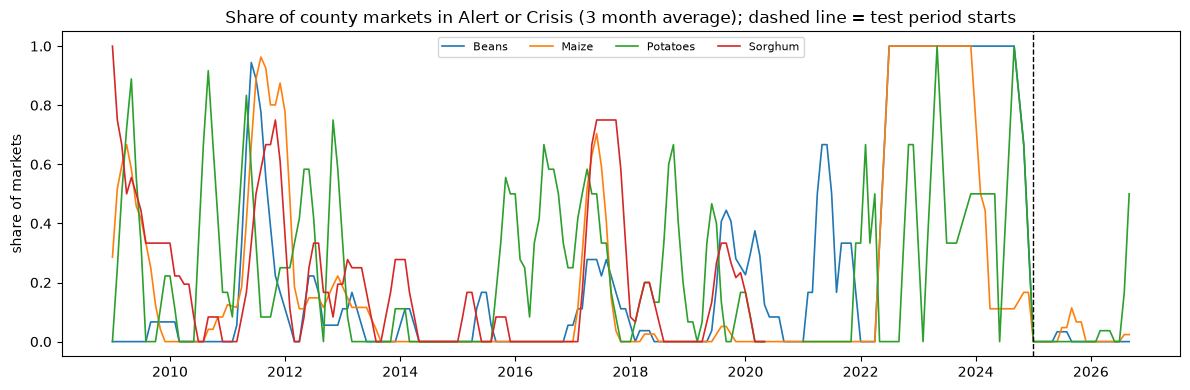

In [3]:
KEYS = ['admin2', 'market', 'crop', 'pricetype']

led['month'] = pd.PeriodIndex(led['month'], freq='M')
county = led.groupby(KEYS + ['month'], as_index=False)['kes_kg'].mean()
months = pd.period_range(county['month'].min(), county['month'].max(), freq='M')

parts = []
for key, g in county.groupby(KEYS):
    if g['kes_kg'].notna().sum() < 37:
        continue
    price = g.set_index('month')['kes_kg'].reindex(months)
    score = alps_scores(price, price.notna())
    df = pd.DataFrame({'month': months, 'price': price.values, 'alps': score.values})
    for k, v in zip(KEYS, key):
        df[k] = v
    parts.append(df.dropna(subset=['alps']))

CA = pd.concat(parts, ignore_index=True)
CA['phase'] = to_phase(CA['alps'])
CA['period'] = np.where(CA['month'] <= pd.Period(TRAIN[1], 'M'), 'train', 'test')

print('Series scored:', CA.groupby(KEYS).ngroups, '| scored market-months:', len(CA))
tab = CA.groupby(['crop', 'period'])['phase'].value_counts().unstack().reindex(columns=PHASES, fill_value=0)
tab['Alert or Crisis %'] = (100 * tab[['Alert', 'Crisis']].sum(axis=1) / tab[PHASES].sum(axis=1)).round(1)
print(tab.to_string())

t = CA[CA['period'] == 'test']
print('\nTest period: series', t.groupby(KEYS).ngroups,
      '| months', t['month'].nunique(),
      '| Alert or Crisis market-months:', int(t['phase'].isin(['Alert', 'Crisis']).sum()))

CA.to_csv(HANDOFF / 'county_alps.csv', index=False)
print('Saved:', HANDOFF / 'county_alps.csv')

share = (CA.assign(hit=CA['phase'].isin(['Alert', 'Crisis']))
           .groupby(['month', 'crop'])['hit'].mean().unstack())
fig, ax = plt.subplots(figsize=(12, 4))
for c in share.columns:
    ax.plot(share.index.to_timestamp(), share[c].rolling(3, min_periods=1).mean(), label=c, lw=1.2)
ax.axvline(pd.Period(TEST[0], 'M').to_timestamp(), ls='--', color='black', lw=1)
ax.set_title('Share of county markets in Alert or Crisis (3 month average); dashed line = test period starts')
ax.set_ylabel('share of markets'); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

**What the output shows**

1. County ALPS scores were calculated for every WFP market series with at least 3 years of real prices. 44 series are active in the test period (2025 to 2026), over 21 months.
2. The test period is very calm. Only 12 market-months reach Alert or Crisis: 0.5% for beans, 2.3% for maize and 6.8% for potatoes. Sorghum has almost no test data.
3. The training years had far more shocks: about 12 to 13% of months for maize and beans, 18% for sorghum and 24% for potatoes.
4. The chart shows shocks arrive in waves across many markets at once (2009, 2011, 2017 and 2021 to 2024), matching drought years. After 2025 almost all markets are Normal, as prices fell after the 2023 peak.
5. The flat peak near 0.9 in 2023 to 2024 likely comes from only a few markets reporting, so it should be read with care.
6. Conclusion: 12 alert months are too few to judge an alert model on the test period alone. We therefore judge the early warning model mainly with year by year backtests and drought replays (Steps 5 and 7), and use the test period as a final check.

## Step 4. Build the early warning dataset

**What this code does:** for every market and month it collects **only what we would have known that month**, and
then records **what happened in the next 3 months**. The model learns the link between the two.

*What we know this month (features):* how far the price is above normal now and in the last 2 months, how much the
price moved in the last 1 and 3 months, county rainfall and vegetation compared with normal, whether it is a dry spell,
the time of year and the maize lean season, how the other price series in the same county are doing, how many markets
nationally are already in Alert, the crop, retail or wholesale, and whether the county is arid or semi arid.

*What happened next (targets):* Alert or Crisis 1, 2 and 3 months ahead, and **Alert or Crisis at any point in the next
3 months** (the early warning target used in the app).

In [4]:
# rainfall, vegetation and dry land class by county
RAW = next((p / 'sokoradar_raw_data' for p in [HANDOFF, *HANDOFF.parents]
            if (p / 'sokoradar_raw_data' / 'counties.csv').exists()), None)
assert RAW is not None, 'sokoradar_raw_data folder not found'
cty = pd.read_csv(RAW / 'counties.csv')
cty['key'] = cty['county'].str.lower().str.replace(r'[^a-z]', '', regex=True)
cl = pd.read_csv(RAW / 'county_climate_chirps_ndvi.csv')
cl['month'] = pd.to_datetime(cl['month']).dt.to_period('M')
cl = cl.rename(columns={'county_pcode': 'pcode'})[['pcode', 'month', 'rain_3m_pct', 'ndvi_pct']]

D = CA[KEYS + ['month', 'price', 'alps', 'phase']].copy()
D['key'] = D['admin2'].str.lower().str.replace(r'[^a-z]', '', regex=True)
D = D.merge(cty[['key', 'pcode', 'asal']], on='key', how='left')
D['asal'] = D['asal'].fillna('Unknown')
D = D.merge(cl, on=['pcode', 'month'], how='left')
D['sid'] = D.groupby(KEYS).ngroup()
D['t'] = D['month'].map(lambda p: p.ordinal)
D = D.sort_values(['sid', 't']).reset_index(drop=True)

def shifted(col, k):
    """Value of `col` k months earlier in the same series (negative k = k months later)."""
    s = D.set_index(['sid', 't'])[col]
    return s.reindex(pd.MultiIndex.from_arrays([D['sid'], D['t'] - k])).values

# what we know this month
D['hit'] = (D['alps'] >= 1).astype(float)
D['alps_1'], D['alps_2'] = shifted('alps', 1), shifted('alps', 2)
D['chg1'] = np.log(D['price'] / shifted('price', 1))
D['chg3'] = np.log(D['price'] / shifted('price', 3))
D['rain_1'] = shifted('rain_3m_pct', 1)
D['dry'] = (D['rain_3m_pct'] < 75).astype(float).where(D['rain_3m_pct'].notna())
mon = D['month'].map(lambda p: p.month)
D['m_sin'], D['m_cos'] = np.sin(2 * np.pi * mon / 12), np.cos(2 * np.pi * mon / 12)
D['lean'] = ((D['crop'] == 'Maize') & mon.isin([5, 6, 7])).astype(float)
grp = D.groupby(['admin2', 't'])['alps']
D['county_others'] = (grp.transform('sum') - D['alps']) / (grp.transform('count') - 1)
D['national_share'] = D.groupby('t')['hit'].transform('mean')
for c in ['Maize', 'Beans', 'Sorghum', 'Potatoes']:
    D[f'crop_{c}'] = (D['crop'] == c).astype(float)
D['retail'] = (D['pricetype'] == 'Retail').astype(float)
D['arid'] = (D['asal'] == 'Arid').astype(float)
D['semi_arid'] = (D['asal'] == 'Semi-arid').astype(float)

# what happened next
for h in (1, 2, 3):
    D[f'y{h}'] = shifted('hit', -h)
Y3 = D[['y1', 'y2', 'y3']]
D['y_any'] = np.where(Y3.max(axis=1) == 1, 1.0, np.where(Y3.notna().all(axis=1), 0.0, np.nan))

FEATURES = ['alps', 'alps_1', 'alps_2', 'chg1', 'chg3', 'rain_3m_pct', 'rain_1', 'ndvi_pct', 'dry',
            'm_sin', 'm_cos', 'lean', 'county_others', 'national_share',
            'crop_Maize', 'crop_Beans', 'crop_Sorghum', 'crop_Potatoes', 'retail', 'arid', 'semi_arid']
LABELS = {'alps': 'Price vs normal now', 'alps_1': 'Price vs normal last month',
          'alps_2': 'Price vs normal 2 months ago', 'chg1': 'Price change last month',
          'chg3': 'Price change last 3 months', 'rain_3m_pct': 'Rainfall last 3 months',
          'rain_1': 'Rainfall a month earlier', 'ndvi_pct': 'Vegetation (NDVI)', 'dry': 'Dry spell',
          'm_sin': 'Time of year', 'm_cos': 'Time of year', 'lean': 'Maize lean season',
          'county_others': 'Other prices in the same county', 'national_share': 'Markets in alert nationally',
          'crop_Maize': 'Crop', 'crop_Beans': 'Crop', 'crop_Sorghum': 'Crop', 'crop_Potatoes': 'Crop',
          'retail': 'Retail or wholesale', 'arid': 'Arid or semi arid county', 'semi_arid': 'Arid or semi arid county'}

print('Rows (market months):', len(D), '| series:', D['sid'].nunique(), '|', D['month'].min(), 'to', D['month'].max())
print('Rows with rainfall:', f"{D['rain_3m_pct'].notna().mean():.0%}")
print('Share of rows followed by Alert or Crisis within 3 months:', f"{D['y_any'].mean():.1%}")
print('Rows with a known 3 month outcome:', int(D['y_any'].notna().sum()))

Rows (market months): 3926 | series: 71 | 2009-01 to 2026-09
Rows with rainfall: 100%
Share of rows followed by Alert or Crisis within 3 months: 22.7%
Rows with a known 3 month outcome: 3400


**How to read the output**

1. **Rows** are market months we can learn from. **Series** is the number of market, crop and price type combinations.
2. **Rows with rainfall** shows how many market months could be linked to a county. If it is low, some WFP county names did not match the county list.
3. **Followed by Alert or Crisis within 3 months** is how common the thing we predict is. It is a minority, so accuracy alone would be misleading; we use recall and precision.
4. **Known 3 month outcome:** the last months of the data have no outcome yet, because the next 3 months have not happened. Those months get a live warning in the app, but cannot be scored.

## Step 5. Backtest year by year, and choose the alert threshold on the training years

**What this code does:** it pretends to be in each year from 2013 to 2024. For each year it trains the model only on
the years before (leaving a 3 month gap so no outcome leaks into the past), predicts that year, then moves on. This gives
an honest prediction for every month from 2013 to 2024 that the model never saw.

It compares the model with two simple rules a county officer could use without any model:
* **Same as now:** "if the market is in Alert now, it will be in Alert" (persistence).
* **ALPS score now:** rank markets by today's score.

Then it picks the **alert threshold**: the chance above which we raise a warning. A missed crisis costs more than a
false alarm, so a miss counts 5 and a false alarm counts 1 (the same rule as notebook 04), and we choose the threshold
with the lowest total cost **on these training year predictions only**.

In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score

COST_MISS, COST_FALSE = 5, 1
TARGETS = {'y1': 1, 'y2': 2, 'y3': 3, 'y_any': 3}          # target and how many months ahead it looks
TRAIN_END = pd.Period(TRAIN[1], 'M').ordinal
TEST_START = pd.Period(TEST[0], 'M').ordinal
YEARS = range(2013, int(TRAIN[1][:4]) + 1)

def make_model():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=250,
                                          l2_regularization=1.0, class_weight='balanced', random_state=42)

def year_start(y):
    return pd.Period(f'{y}-01', 'M').ordinal

def best_threshold(y, p):
    grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
    cost = [COST_MISS * ((p < g) & (y == 1)).sum() + COST_FALSE * ((p >= g) & (y == 0)).sum() for g in grid]
    return float(grid[int(np.argmin(cost))])

def summary(y, p, thr, alps_now):
    pred, same = p >= thr, alps_now >= 1
    return {'events': int(y.sum()), 'rows': len(y),
            'AUC model': roc_auc_score(y, p), 'AUC ALPS now': roc_auc_score(y, alps_now),
            'recall model': recall_score(y, pred), 'precision model': precision_score(y, pred, zero_division=0),
            'recall same as now': recall_score(y, same), 'precision same as now': precision_score(y, same, zero_division=0)}

# year by year backtest (out of fold predictions)
for target, h in TARGETS.items():
    D[f'p_{target}'] = np.nan
    for yr in YEARS:
        start = year_start(yr)
        tr = D[target].notna() & (D['t'] + h < start)
        te = D[target].notna() & (D['t'] >= start) & (D['t'] < year_start(yr + 1)) & (D['t'] + h <= TRAIN_END)
        if tr.sum() < 200 or D.loc[tr, target].nunique() < 2 or te.sum() == 0:
            continue
        model = make_model().fit(D.loc[tr, FEATURES], D.loc[tr, target])
        D.loc[te, f'p_{target}'] = model.predict_proba(D.loc[te, FEATURES])[:, 1]

THRESHOLDS, BACKTEST = {}, []
for target in TARGETS:
    m = D[f'p_{target}'].notna() & D[target].notna()
    y, p = D.loc[m, target].values, D.loc[m, f'p_{target}'].values
    THRESHOLDS[target] = best_threshold(y, p)
    BACKTEST.append({'target': target, 'threshold': THRESHOLDS[target], **summary(y, p, THRESHOLDS[target], D.loc[m, 'alps'].values)})
BACKTEST = pd.DataFrame(BACKTEST).set_index('target')
THR = THRESHOLDS['y_any']
print('Backtest years:', YEARS[0], 'to', YEARS[-1], '| alert threshold for the early warning (within 3 months):', THR)
print(BACKTEST.round(2).to_string())

Backtest years: 2013 to 2024 | alert threshold for the early warning (within 3 months): 0.45
        threshold  events  rows  AUC model  AUC ALPS now  recall model  precision model  recall same as now  precision same as now
target                                                                                                                            
y1           0.22     249  2362       0.94          0.94          0.86             0.48                0.71                   0.71
y2           0.38     243  2308       0.88          0.87          0.72             0.42                0.56                   0.56
y3           0.45     240  2276       0.81          0.79          0.62             0.34                0.43                   0.44
y_any        0.45     389  2237       0.87          0.86          0.72             0.56                0.50                   0.80


**How to read the output**

1. **Rows `y1`, `y2`, `y3`:** predicting Alert or Crisis exactly 1, 2 or 3 months ahead. **Row `y_any`:** Alert or Crisis at any point in the next 3 months. This is the early warning used in the app.
2. **AUC** (0.5 = guessing, 1 = perfect) shows how well the model ranks risky markets above safe ones. Compare **AUC model** with **AUC ALPS now**: the model must beat today's score to be worth using.
3. **Recall** is the share of real Alert or Crisis months we warned about. **Precision** is the share of warnings that were right. The project target is recall of at least 0.70 with precision of at least 0.50.
4. **Same as now** is the rule "if it is in Alert now, it stays in Alert". It is hard to beat 1 month ahead, but it can never warn **before** an alert starts. The model's value shows most at 2 to 3 months ahead and in Step 7 (lead time).
5. **Threshold** is the chance above which we warn, chosen by cost on these training years only.

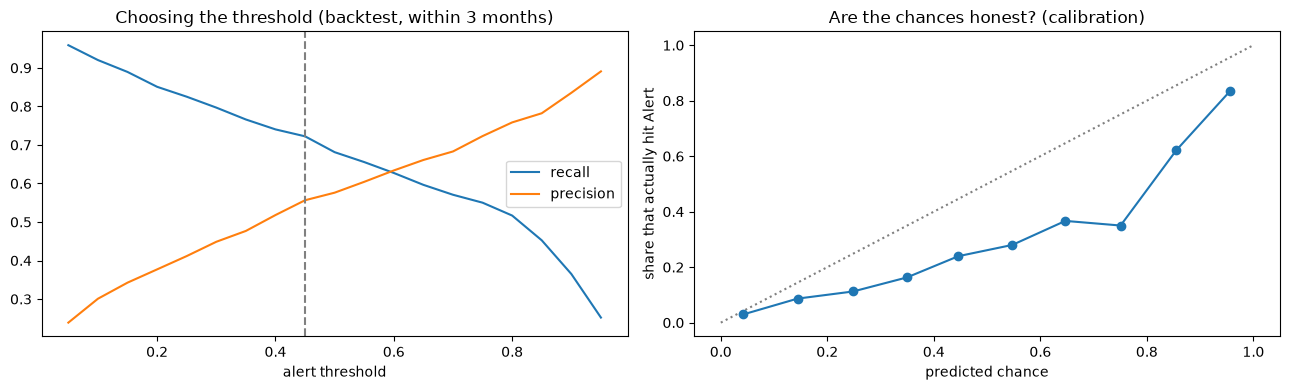

In [6]:
# threshold trade-off and calibration on the backtest (early warning target)
m = D['p_y_any'].notna() & D['y_any'].notna()
y, p = D.loc[m, 'y_any'].values, D.loc[m, 'p_y_any'].values
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
CURVE = pd.DataFrame({'threshold': grid,
                      'recall': [recall_score(y, p >= g) for g in grid],
                      'precision': [precision_score(y, p >= g, zero_division=0) for g in grid],
                      'cost': [COST_MISS * ((p < g) & (y == 1)).sum() + COST_FALSE * ((p >= g) & (y == 0)).sum() for g in grid]})
bins = pd.cut(p, np.linspace(0, 1, 11), include_lowest=True)
CALIB = (pd.DataFrame({'p': p, 'y': y, 'bin': bins}).groupby('bin', observed=True)
           .agg(predicted=('p', 'mean'), observed=('y', 'mean'), rows=('y', 'size')).reset_index(drop=True))

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(CURVE.threshold, CURVE.recall, label='recall'); axs[0].plot(CURVE.threshold, CURVE.precision, label='precision')
axs[0].axvline(THR, ls='--', color='grey'); axs[0].set_xlabel('alert threshold'); axs[0].legend()
axs[0].set_title('Choosing the threshold (backtest, within 3 months)')
axs[1].plot([0, 1], [0, 1], ls=':', color='grey'); axs[1].plot(CALIB.predicted, CALIB.observed, marker='o')
axs[1].set_xlabel('predicted chance'); axs[1].set_ylabel('share that actually hit Alert')
axs[1].set_title('Are the chances honest? (calibration)')
plt.tight_layout(); plt.show()

**How to read the charts**

1. **Left:** as the threshold goes up, we raise fewer warnings, so precision rises and recall falls. The dashed line is the threshold chosen by cost (a miss costs 5, a false alarm 1).
2. **Right:** each dot compares the predicted chance with how often Alert actually followed. Dots near the dotted line mean the chances can be read at face value. With `class_weight='balanced'` the model tends to give chances that are too high, so the app shows them as a **ranking and a warning**, not as exact probabilities.

## Step 6. Final test on 2025 to 2026 (run once)

**What this code does:** it trains one final model on all the training years (outcomes up to December 2024), then
predicts every month from the end of 2024 to the latest month. Months with a known outcome are scored once. The latest
months have no outcome yet: these are the **live warnings** for the next 3 months shown in the app.

In [7]:
FINAL = {}
for target, h in TARGETS.items():
    tr = D[target].notna() & (D['t'] + h <= TRAIN_END)
    FINAL[target] = make_model().fit(D.loc[tr, FEATURES], D.loc[tr, target])
    live = D[f'p_{target}'].isna() & (D['t'] > TRAIN_END - h)
    D.loc[live, f'p_{target}'] = FINAL[target].predict_proba(D.loc[live, FEATURES])[:, 1]

D['source'] = np.where(D['t'] >= TEST_START, 'test', np.where(D['p_y_any'].notna(), 'backtest', ''))
te = (D['t'] >= TEST_START) & D['y_any'].notna()
TEST_RESULT = {}
if te.sum() and D.loc[te, 'y_any'].nunique() == 2:
    TEST_RESULT = summary(D.loc[te, 'y_any'].values, D.loc[te, 'p_y_any'].values, THR, D.loc[te, 'alps'].values)
    print(pd.Series(TEST_RESULT).round(2).to_string())
else:
    print('Test period has no Alert months with a known outcome, so recall cannot be measured.')
print('\nLive warnings for the latest month:', D['month'].max())
latest = D[D['month'] == D['month'].max()].sort_values('p_y_any', ascending=False)
print(latest[KEYS + ['phase', 'p_y_any']].head(10).round(2).to_string(index=False))

events                    15.00
rows                     174.00
AUC model                  0.76
AUC ALPS now               0.84
recall model               0.60
precision model            0.38
recall same as now         0.07
precision same as now      0.33

Live warnings for the latest month: 2026-09
 admin2             market     crop pricetype  phase  p_y_any
Turkana Mogadishu (Kakuma) Potatoes    Retail  Alert     0.78
Turkana Mogadishu (Kakuma)    Maize    Retail Normal     0.30
Turkana  Ethiopia (Kakuma)  Sorghum    Retail Normal     0.15
Turkana Mogadishu (Kakuma)    Beans    Retail Normal     0.13
Turkana  HongKong (Kakuma)    Beans    Retail Normal     0.11
Garissa       IFO (Daadab)    Beans    Retail Normal     0.10
Garissa       IFO (Daadab)    Maize    Retail Normal     0.10
Turkana  Ethiopia (Kakuma)    Beans    Retail Normal     0.08
Turkana  HongKong (Kakuma)    Maize    Retail Normal     0.04
Turkana  Ethiopia (Kakuma)    Maize    Retail Normal     0.02


**How to read the output**

1. **Test results:** the same measures as Step 5, on 2025 to 2026, run once. Look at **events** first: with very few Alert months (the test period was calm), recall can jump a lot with one hit or one miss, so these numbers are a check, not the main evidence.
2. **Live warnings:** markets ranked by the chance of hitting Alert or Crisis in the next 3 months. These feed the app.

## Step 7. Lead time: how many months earlier do we warn?

**What this code does:** it finds every **new alert**: a month that hits Alert or Crisis after at least 3 months
without one. WFP's current ALPS only flags it in that month (0 months of warning). We check whether SokoRadar warned
1, 2 or 3 months **before**, using the honest backtest predictions from Step 5.

For **2011**, the backtest has too little earlier data, so we train on every training year **except** October 2010 to
December 2011 and predict that drought. This is a fair test of a drought the model never saw, but unlike the other
years it uses later years for training, and we say so.

In [8]:
EPISODES = {'2011 drought': ('2010-10', '2011-12'), '2017 drought': ('2016-10', '2017-12'),
            '2022 drought': ('2021-10', '2022-12')}

# 2011: leave the episode out, train on everything else in the training years
a, b = (pd.Period(x, 'M').ordinal for x in EPISODES['2011 drought'])
tr = D['y_any'].notna() & ((D['t'] + 3 < a) | (D['t'] > b)) & (D['t'] + 3 <= TRAIN_END)
win = (D['t'] >= a - 3) & (D['t'] <= b)
D.loc[win, 'p_y_any'] = make_model().fit(D.loc[tr, FEATURES], D.loc[tr, 'y_any']).predict_proba(D.loc[win, FEATURES])[:, 1]
D.loc[win, 'source'] = 'replay 2011'

# new alerts and how early we warned
D['warn'] = (D['p_y_any'] >= THR).astype(float).where(D['p_y_any'].notna())
before = np.column_stack([shifted('hit', k) for k in (1, 2, 3)])
warned = np.column_stack([shifted('warn', k) for k in (1, 2, 3)])
D['new_alert'] = (D['hit'] == 1) & ~(before == 1).any(axis=1)
D['lead'] = np.select([warned[:, 2] == 1, warned[:, 1] == 1, warned[:, 0] == 1], [3, 2, 1], 0)
D['can_check'] = ~np.isnan(warned).all(axis=1)

EV = D[D['new_alert'] & D['can_check']].copy()
EV['episode'] = 'Other years'
for name, (s, e) in EPISODES.items():
    EV.loc[(EV['month'] >= pd.Period(s, 'M')) & (EV['month'] <= pd.Period(e, 'M')), 'episode'] = name

def lead_table(ev, rows):
    w = rows[(rows['warn'] == 1) & rows['y_any'].notna()]
    return pd.Series({'new alerts': len(ev), 'warned 1+ months early': int((ev['lead'] > 0).sum()),
                      'share warned early': (ev['lead'] > 0).mean() if len(ev) else np.nan,
                      'average lead when warned (months)': ev.loc[ev['lead'] > 0, 'lead'].mean(),
                      'warnings that came true': w['y_any'].mean() if len(w) else np.nan})

def in_window(df, s, e):
    return df[(df['month'] >= pd.Period(s, 'M')) & (df['month'] <= pd.Period(e, 'M'))]

LEAD = pd.DataFrame({name: lead_table(EV[EV['episode'] == name], in_window(D, s, e))
                     for name, (s, e) in EPISODES.items()})
LEAD['All backtest years'] = lead_table(EV[EV['source'] == 'backtest'], D[D['source'] == 'backtest'])
print('WFP current ALPS warns 0 months before each new alert. SokoRadar:')
print(LEAD.T.round(2).to_string())

WFP current ALPS warns 0 months before each new alert. SokoRadar:
                    new alerts  warned 1+ months early  share warned early  average lead when warned (months)  warnings that came true
2011 drought              21.0                    18.0                0.86                               2.11                     0.74
2017 drought              17.0                    15.0                0.88                               2.13                     0.63
2022 drought               4.0                     2.0                0.50                               2.00                     0.84
All backtest years        60.0                    45.0                0.75                               2.16                     0.56


**How to read the output**

1. **New alerts** is the number of times a market moved into Alert or Crisis after a calm spell, in each drought and over all backtest years.
2. **Warned 1+ months early** is how many of those SokoRadar flagged before they happened. WFP's current ALPS flags 0 of them early, because it only reacts once prices are already high.
3. **Average lead** is how many months of warning we gave when we did warn (1 to 3).
4. **Warnings that came true** is the check on the lead time: a system that warns every month would catch every alert early but be useless. Read the lead time together with this number.
5. This is the headline for the panel: *"In the 2017 drought SokoRadar warned X of Y new alerts at least a month early, on average Z months ahead."*
6. **2011** comes from a leave-the-drought-out model, so state that next to its numbers.

## Step 8. What drives the warnings, and save everything for the app

**What this code does:** it measures which information the early warning model relies on most (permutation
importance: how much worse the model gets when one piece of information is shuffled), then saves the predictions,
metrics and lead times for the app.

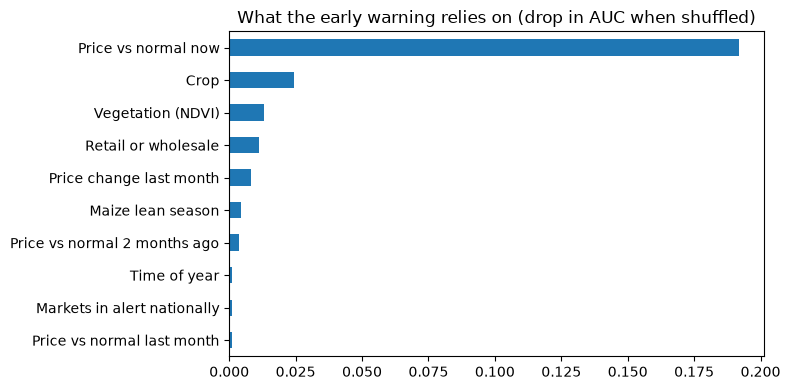

Saved: ew_predictions.csv, ew_events.csv and ew_metrics.json in c:\Users\siraa\OneDrive\Desktop\Data-science\sokoradar\output\modelling\handoff


In [9]:
from sklearn.inspection import permutation_importance

cut = year_start(2019)
tr = D['y_any'].notna() & (D['t'] + 3 < cut)
ev = D['y_any'].notna() & (D['t'] >= cut) & (D['t'] + 3 <= TRAIN_END)
imp_model = make_model().fit(D.loc[tr, FEATURES], D.loc[tr, 'y_any'])
pi = permutation_importance(imp_model, D.loc[ev, FEATURES], D.loc[ev, 'y_any'], scoring='roc_auc',
                            n_repeats=5, random_state=42)
IMPORTANCE = (pd.Series(pi.importances_mean, index=FEATURES).rename(index=LABELS)
                .groupby(level=0).sum().clip(lower=0).sort_values(ascending=False))
IMPORTANCE.head(10).iloc[::-1].plot.barh(figsize=(8, 4), title='What the early warning relies on (drop in AUC when shuffled)')
plt.tight_layout(); plt.show()

# group results for the app (backtest, at the chosen threshold)
m = D['p_y_any'].notna() & D['y_any'].notna() & (D['source'] == 'backtest')
def by(col):
    g = D[m].groupby(col)
    return pd.DataFrame({'events': g['y_any'].sum(), 'rows': g.size(),
                         'recall': g.apply(lambda d: recall_score(d['y_any'], d['p_y_any'] >= THR) if d['y_any'].sum() else np.nan),
                         'precision': g.apply(lambda d: precision_score(d['y_any'], d['p_y_any'] >= THR, zero_division=0))}).reset_index()

OUT = D[KEYS + ['month', 'alps', 'phase', 'p_y1', 'p_y2', 'p_y3', 'p_y_any', 'warn', 'y_any', 'source']].copy()
OUT = OUT.rename(columns={'p_y_any': 'p_any'})
OUT.to_csv(HANDOFF / 'ew_predictions.csv', index=False)
EV[KEYS + ['month', 'lead', 'episode', 'source']].to_csv(HANDOFF / 'ew_events.csv', index=False)
json.dump({
    'threshold': THR, 'thresholds': THRESHOLDS, 'cost_miss': COST_MISS, 'cost_false': COST_FALSE,
    'backtest_years': [YEARS[0], YEARS[-1]],
    'backtest': BACKTEST.reset_index().round(4).to_dict('records'),
    'test': {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in TEST_RESULT.items()},
    'curve': CURVE.round(4).to_dict('records'), 'calibration': CALIB.round(4).to_dict('records'),
    'by_crop': by('crop').round(4).to_dict('records'), 'by_asal': by('asal').round(4).to_dict('records'),
    'lead': LEAD.T.reset_index().rename(columns={'index': 'period'}).round(3).to_dict('records'),
    'importance': IMPORTANCE.round(4).reset_index().rename(columns={'index': 'driver', 0: 'importance'}).to_dict('records'),
}, open(HANDOFF / 'ew_metrics.json', 'w'), indent=1, default=float)
print('Saved: ew_predictions.csv, ew_events.csv and ew_metrics.json in', HANDOFF)

**How to read the output**

1. **The chart** lists the information the warnings rely on most. If rainfall, vegetation or the dry spell flag are near the top, the model is using the early signals the EDA found (a dry spell adds about 15 points to the 3 month maize rise), not just copying today's price.
2. **Saved files** feed the app: the warnings for every market and month, the lead time of every new alert, and the model quality numbers. Run `python prepare_data.py` in `alerts_app` afterwards so the app picks them up.